# VaDeSC on SUPPORT

Baselines, VaDeSC, cluster interpretation and the robustness experiments (leakage, seeds, number of clusters, survival distribution), plus the extra datasets.

The full run takes roughly 30-45 min on a laptop CPU. Set `QUICK = True` for a short check.

In [1]:
import sys
sys.path.append("..")

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from src.baselines import run_cox, run_rsf, run_weibull_aft
from src.data import load_sksurv, load_support, load_support_raw
from src.metrics import logrank_chi2
from src.vadesc import DEVICE, evaluate_vadesc, train_vadesc

QUICK = False
EPOCHS = 60 if QUICK else 300
N_SEEDS = 3 if QUICK else 5
print("device:", DEVICE)

device: cpu


## Data

(9105, 47) | death rate 68.1% | median follow-up 233 days


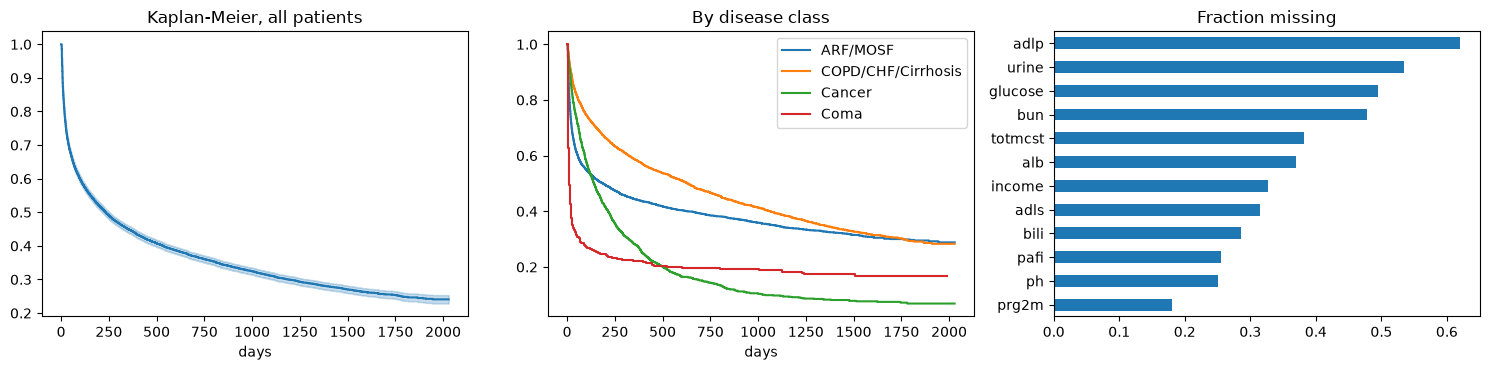

In [2]:
raw = load_support_raw()
print(raw.shape, f"| death rate {raw['death'].mean():.1%} | median follow-up {raw['d.time'].median():.0f} days")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
KaplanMeierFitter().fit(raw["d.time"], raw["death"]).plot_survival_function(ax=ax[0], legend=False)
ax[0].set(title="Kaplan-Meier, all patients", xlabel="days")
for dz, g in raw.groupby("dzclass"):
    KaplanMeierFitter(label=dz).fit(g["d.time"], g["death"]).plot_survival_function(ax=ax[1], ci_show=False)
ax[1].set(title="By disease class", xlabel="days")
raw.isna().mean().sort_values(ascending=False).head(12).plot.barh(ax=ax[2])
ax[2].set(title="Fraction missing"); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

In [3]:
support = load_support()
print(f"train {support.X_tr.shape}, val {support.X_va.shape}, test {support.X_te.shape}")

train (6373, 59), val (911, 59), test (1821, 59)


## Baselines and VaDeSC

In [4]:
results = {
    "Cox PH": run_cox(support),
    "RSF": run_rsf(support),
    "Weibull AFT": run_weibull_aft(support),
}
vadesc = train_vadesc(support, K=4, d_lat=16, weibull_k=2.0, epochs=EPOCHS, verbose=True)  # configs/support.yml
results["VaDeSC"], clusters, z_te = evaluate_vadesc(vadesc, support)
pd.DataFrame(results).T.round(3)

epoch   25 | -ELBO    38.395 | val C-index 0.702
epoch   50 | -ELBO    37.141 | val C-index 0.720
epoch   75 | -ELBO    36.716 | val C-index 0.736
epoch  100 | -ELBO    36.368 | val C-index 0.749
epoch  125 | -ELBO    36.107 | val C-index 0.752
epoch  150 | -ELBO    35.912 | val C-index 0.755
epoch  175 | -ELBO    35.707 | val C-index 0.768
epoch  200 | -ELBO    35.605 | val C-index 0.778
epoch  225 | -ELBO    35.497 | val C-index 0.771
epoch  250 | -ELBO    35.433 | val C-index 0.778
epoch  275 | -ELBO    35.359 | val C-index 0.784
epoch  300 | -ELBO    35.283 | val C-index 0.791


,C-index,IBS,log-rank chi2
Cox PH,0.805,0.147,NaN
RSF,0.806,0.136,NaN
Weibull AFT,0.804,0.145,NaN
VaDeSC,0.800,0.158,574.083


## Clusters

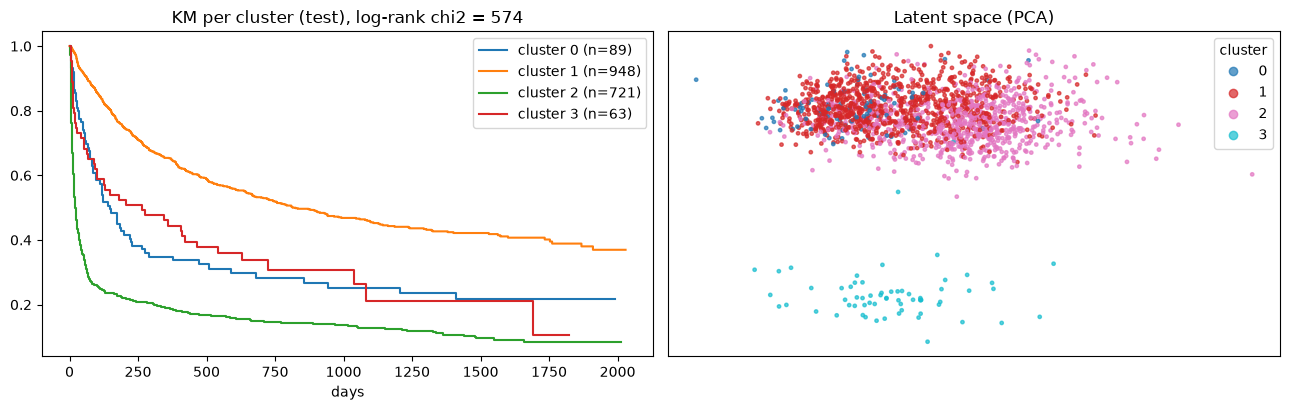

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for k in np.unique(clusters):
    m = clusters == k
    KaplanMeierFitter(label=f"cluster {k} (n={m.sum()})").fit(support.t_te[m], support.e_te[m]) \
        .plot_survival_function(ax=ax[0], ci_show=False)
ax[0].set(title=f"KM per cluster (test), log-rank chi2 = {logrank_chi2(support, clusters):.0f}", xlabel="days")
p = PCA(2).fit_transform(z_te)
sc = ax[1].scatter(p[:, 0], p[:, 1], c=clusters, s=6, cmap="tab10", alpha=0.7)
ax[1].set(title="Latent space (PCA)", xticks=[], yticks=[])
ax[1].legend(*sc.legend_elements(), title="cluster")
plt.tight_layout(); plt.show()

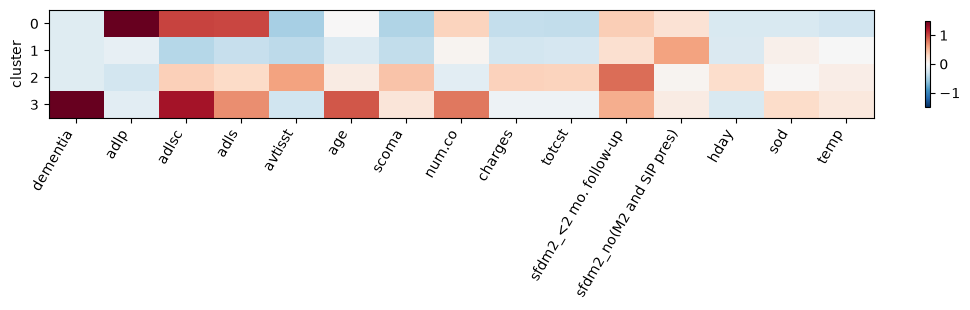

dzclass,ARF/MOSF,COPD/CHF/Cirrhosis,Cancer,Coma
cluster,,,,
0,0.31,0.51,0.18,0.00
1,0.38,0.41,0.20,0.01
2,0.61,0.14,0.12,0.13
3,0.59,0.29,0.03,0.10


In [6]:
# mean standardised feature value per cluster, 15 most different features
prof = pd.DataFrame(support.X_te, columns=support.features).groupby(clusters).mean()
top = prof.var().sort_values(ascending=False).index[:15]
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(prof[top].to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set(xticks=range(len(top)), yticks=range(len(prof)), ylabel="cluster")
ax.set_xticklabels(top, rotation=60, ha="right"); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

pd.crosstab(pd.Series(clusters, name="cluster"), support.raw_te["dzclass"], normalize="index").round(2)

## Feature leakage

`sfdm2`, `slos`, `charges` and `totcst` are recorded after study entry. The `sfdm2` level `"<2 mo. follow-up"` mostly means the patient died within two months.

In [7]:
support_clean = load_support(drop_post_baseline=True)
leak = {}
for name, d in [("paper preprocessing", support), ("baseline-only", support_clean)]:
    leak[(name, "Cox PH")] = run_cox(d)["C-index"]
    leak[(name, "RSF")] = run_rsf(d)["C-index"]
    leak[(name, "VaDeSC")] = evaluate_vadesc(train_vadesc(d, epochs=EPOCHS), d)[0]["C-index"]
pd.Series(leak).unstack(0).round(3)

,baseline-only,paper preprocessing
Cox PH,0.732,0.805
RSF,0.724,0.806
VaDeSC,0.629,0.800


## Stability across seeds

In [8]:
runs = []
for s in range(N_SEEDS):
    m, cl, _ = evaluate_vadesc(train_vadesc(support, seed=s, epochs=EPOCHS), support)
    runs.append({"seed": s, **m, "clusters": cl})
runs = pd.DataFrame(runs)
ari = [adjusted_rand_score(a, b) for a, b in combinations(runs["clusters"], 2)]
print(f"C-index {runs['C-index'].mean():.3f} +/- {runs['C-index'].std():.3f}")
print(f"pairwise ARI {np.mean(ari):.2f} +/- {np.std(ari):.2f} (min {np.min(ari):.2f})")
print("cluster sizes:", [np.bincount(c).tolist() for c in runs["clusters"]])
runs.drop(columns="clusters").round(3)

C-index 0.780 +/- 0.017
pairwise ARI 0.42 +/- 0.14 (min 0.24)
cluster sizes: [[895, 107, 61, 758], [942, 61, 760, 58], [610, 76, 466, 669], [500, 451, 809, 61], [770, 73, 788, 190]]


,seed,C-index,IBS,log-rank chi2
0,0,0.763,0.170,296.899
1,1,0.766,0.172,305.006
2,2,0.776,0.159,862.047
3,3,0.794,0.157,719.670
4,4,0.803,0.153,294.324


## Number of clusters

In [9]:
rows = []
for K in [1, 2, 3, 4, 6, 8]:
    model = train_vadesc(support, K=K, epochs=EPOCHS)
    m, cl, _ = evaluate_vadesc(model, support)
    rows.append({"K": K, **m, "used clusters": len(np.unique(cl)), "final -ELBO": model.history.train_loss.iloc[-1]})
pd.DataFrame(rows).set_index("K").round(3)

,C-index,IBS,log-rank chi2,used clusters,final -ELBO
K,,,,,
1,0.803,0.174,NaN,1,35.668
2,0.813,0.155,341.662,2,35.215
3,0.801,0.160,630.035,3,35.242
4,0.800,0.158,574.083,4,35.283
6,0.757,0.163,494.548,6,35.068
8,0.775,0.158,594.313,8,35.081


## Survival distribution and unsupervised clustering

In [10]:
abl = {"Weibull k=2": results["VaDeSC"]}
abl["Weibull k=1"] = evaluate_vadesc(train_vadesc(support, weibull_k=1.0, epochs=EPOCHS), support)[0]
abl["log-normal"] = evaluate_vadesc(train_vadesc(support, dist="lognormal", epochs=EPOCHS), support)[0]
abl["VaDE (no survival)"], cl_vade, _ = evaluate_vadesc(train_vadesc(support, survival=False, epochs=EPOCHS), support)
cl_km = KMeans(4, n_init=10, random_state=42).fit(support.X_tr).predict(support.X_te)
abl["k-means"] = {"log-rank chi2": logrank_chi2(support, cl_km)}
print("ARI(VaDeSC, VaDE) =", round(adjusted_rand_score(clusters, cl_vade), 2),
      "| ARI(VaDeSC, k-means) =", round(adjusted_rand_score(clusters, cl_km), 2))
pd.DataFrame(abl).T.round(3)

ARI(VaDeSC, VaDE) = 0.36 | ARI(VaDeSC, k-means) = 0.26


,C-index,IBS,log-rank chi2
Weibull k=2,0.800,0.158,574.083
Weibull k=1,0.771,0.161,158.903
log-normal,0.793,0.149,364.558
VaDE (no survival),NaN,NaN,111.475
k-means,NaN,NaN,34.676


## Other datasets

From scikit-survival. Smaller latent space as in the paper's FLChain config (`latent_dim=4, K=2, weibull_shape=1`).

In [11]:
extra = {}
for name in ["FLChain", "GBSG2", "WHAS500"]:
    d = load_sksurv(name)
    extra[(name, "Cox PH")] = run_cox(d)
    extra[(name, "RSF")] = run_rsf(d)
    extra[(name, "VaDeSC")] = evaluate_vadesc(train_vadesc(d, K=2, d_lat=4, weibull_k=1.0, epochs=EPOCHS), d)[0]
pd.DataFrame(extra).T.round(3)

C-index    IBS  log-rank chi2
FLChain Cox PH    0.798  0.111            NaN
        RSF       0.798  0.111            NaN
        VaDeSC    0.799  0.113        203.495
GBSG2   Cox PH    0.683  0.177            NaN
        RSF       0.711  0.165            NaN
        VaDeSC    0.662  0.179          0.009
WHAS500 Cox PH    0.830  0.140            NaN
        RSF       0.801  0.163            NaN
        VaDeSC    0.827  0.155         31.088